In [1]:
import sys
%pip install spacy
!{sys.executable} -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     -- ------------------------------------- 0.8/12.8 MB 2.5 MB/s eta 0:00:05
     ---- ----------------------------------- 1.6/12.8 MB 2.8 MB/s eta 0:00:04
     ------ --------------------------------- 2.1/12.8 MB 2.6 MB/s eta 0:00:05
     --------- ------------------------------ 3.1/12.8 MB 3.2 MB/s eta 0:00:03
     ------------ --------------------------- 3.9/12.8 MB 3.3 MB/s eta 0:00:03
     -------------- ------------------------- 4.7/12.8 MB 3.4 MB/s eta 0:00:03
     ----------------- ---------------------- 5.5/12.8 MB 3.4 MB/s eta 0:00:03
     ------------------- -------------------- 6.3/12.8 MB 3.5 MB/s eta 0:00:02
     -------------------- ------------------- 6.6/12.8 MB 3.5 MB/s eta 0:00:02
     ---------------------- ----------------- 7.3/12.8 MB 3.3 MB/s eta 0:00:02


In [2]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub
import pandas as pd
import os


path = kagglehub.dataset_download("wcukierski/enron-email-dataset")
print("📂 تم تحميل الداتا سيت في المسار:", path)


csv_file_path = os.path.join(path, "emails.csv")


df = pd.read_csv(csv_file_path, nrows=1000)


df.head()

📂 تم تحميل الداتا سيت في المسار: C:\Users\Dell\.cache\kagglehub\datasets\wcukierski\enron-email-dataset\versions\2


,file,message
0,allen-p/_sent_mail/1.,Message-ID: <18782981.1075855378110.JavaMail.e...
1,allen-p/_sent_mail/10.,Message-ID: <15464986.1075855378456.JavaMail.e...
2,allen-p/_sent_mail/100.,Message-ID: <24216240.1075855687451.JavaMail.e...
3,allen-p/_sent_mail/1000.,Message-ID: <13505866.1075863688222.JavaMail.e...
4,allen-p/_sent_mail/1001.,Message-ID: <30922949.1075863688243.JavaMail.e...


In [4]:
print(df['message'][0])

Message-ID: <18782981.1075855378110.JavaMail.evans@thyme>
Date: Mon, 14 May 2001 16:39:00 -0700 (PDT)
From: phillip.allen@enron.com
To: tim.belden@enron.com
Subject: 
Mime-Version: 1.0
Content-Type: text/plain; charset=us-ascii
Content-Transfer-Encoding: 7bit
X-From: Phillip K Allen
X-To: Tim Belden <Tim Belden/Enron@EnronXGate>
X-cc: 
X-bcc: 
X-Folder: \Phillip_Allen_Jan2002_1\Allen, Phillip K.\'Sent Mail
X-Origin: Allen-P
X-FileName: pallen (Non-Privileged).pst

Here is our forecast

 


In [5]:
print( df.shape)
print(list(df.columns))

(1000, 2)
['file', 'message']


In [6]:
print( df['message'].isnull().sum())
print((df['message'].dropna().str.strip() == "").sum())
print( df.duplicated(subset=['message']).sum())

0
0
0


In [7]:
char_lengths = df['message'].dropna().apply(len)
word_lengths = df['message'].dropna().apply(lambda x: len(x.split()))

print(char_lengths.min(), word_lengths.min())
print(int(char_lengths.mean()), int(word_lengths.mean()))
print(char_lengths.max(), word_lengths.max())

434 39
1394 175
16884 2272


In [8]:
print(df['message'].str.contains(r'Message-ID:|Mime-Version:|X-Folder:', na=False).sum())
print(df['message'].str.contains(r'<[^>]+>', na=False).sum())
print(df['message'].str.contains(r'http[s]?://|www\.', na=False).sum())
print(df['message'].str.contains(r'\n{2,}|\s{2,}', na=False).sum())

1000
1000
97
1000


In [9]:
print(df['message'].str.contains(r'Date:', na=False).sum())
print(df['message'].str.contains(r'X-From:|X-To:', na=False).sum())
print(df['message'].str.contains(r'(deal|contract|invoice|order|po|ref|#)\s*[:#-]?\s*\d+', case=False, na=False).sum())
print(df['message'].str.contains(r'\b(gas|power|electricity|capacity|contract|software|system)\b', case=False, na=False).sum())

1000
1000


C:\Users\Dell\AppData\Local\Temp\ipykernel_19740\759385544.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(df['message'].str.contains(r'(deal|contract|invoice|order|po|ref|#)\s*[:#-]?\s*\d+', case=False, na=False).sum())


66


C:\Users\Dell\AppData\Local\Temp\ipykernel_19740\759385544.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(df['message'].str.contains(r'\b(gas|power|electricity|capacity|contract|software|system)\b', case=False, na=False).sum())


259


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   file     1000 non-null   object
 1   message  1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB


In [11]:
df.tail()

,file,message
995,allen-p/all_documents/458.,Message-ID: <20430828.1075855696096.JavaMail.e...
996,allen-p/all_documents/459.,Message-ID: <18425275.1075855696118.JavaMail.e...
997,allen-p/all_documents/46.,Message-ID: <24036204.1075855666506.JavaMail.e...
998,allen-p/all_documents/460.,Message-ID: <33307764.1075855696139.JavaMail.e...
999,allen-p/all_documents/461.,Message-ID: <15009418.1075855696162.JavaMail.e...


In [12]:
df.head()

,file,message
0,allen-p/_sent_mail/1.,Message-ID: <18782981.1075855378110.JavaMail.e...
1,allen-p/_sent_mail/10.,Message-ID: <15464986.1075855378456.JavaMail.e...
2,allen-p/_sent_mail/100.,Message-ID: <24216240.1075855687451.JavaMail.e...
3,allen-p/_sent_mail/1000.,Message-ID: <13505866.1075863688222.JavaMail.e...
4,allen-p/_sent_mail/1001.,Message-ID: <30922949.1075863688243.JavaMail.e...


In [13]:
df.duplicated(subset=['message']).sum()

np.int64(0)

In [14]:
df.columns.tolist()

['file', 'message']

In [15]:
df.dtypes

file       object
message    object
dtype: object

In [16]:

text_column = "message"


df["original_text"] = df[text_column].copy()


df["cleaned_text"] = df["original_text"].astype("string").str.strip()


df["cleaned_text"] = df["cleaned_text"].str.replace(
    r"\s+", " ", regex=True
)


display(df[["original_text", "cleaned_text"]].head())

,original_text,cleaned_text
0,Message-ID: <18782981.1075855378110.JavaMail.e...,Message-ID: <18782981.1075855378110.JavaMail.e...
1,Message-ID: <15464986.1075855378456.JavaMail.e...,Message-ID: <15464986.1075855378456.JavaMail.e...
2,Message-ID: <24216240.1075855687451.JavaMail.e...,Message-ID: <24216240.1075855687451.JavaMail.e...
3,Message-ID: <13505866.1075863688222.JavaMail.e...,Message-ID: <13505866.1075863688222.JavaMail.e...
4,Message-ID: <30922949.1075863688243.JavaMail.e...,Message-ID: <30922949.1075863688243.JavaMail.e...


In [17]:
import re
import pandas as pd

def clean_text(text):

    
    if pd.isna(text):
        return text

    text = str(text)

    
    text = re.sub(r"<[^>]+>", " ", text)

    
    text = re.sub(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]", " ", text)

    
    text = re.sub(r"\s+", " ", text)

    return text.strip()



df["cleaned_text"] = df["cleaned_text"].apply(clean_text)


display(df[["original_text", "cleaned_text"]].head())

,original_text,cleaned_text
0,Message-ID: <18782981.1075855378110.JavaMail.e...,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0..."
1,Message-ID: <15464986.1075855378456.JavaMail.e...,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07..."
2,Message-ID: <24216240.1075855687451.JavaMail.e...,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0..."
3,Message-ID: <13505866.1075863688222.JavaMail.e...,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0..."
4,Message-ID: <30922949.1075863688243.JavaMail.e...,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0..."


In [18]:
import re
import pandas as pd

def remove_extra_whitespaces(text):

    if pd.isna(text):
        return text

    text = str(text)

    
    text = re.sub(r"\s+", " ", text)

    return text.strip()



df["cleaned_text"] = df["cleaned_text"].apply(
    remove_extra_whitespaces
)


display(df[["original_text", "cleaned_text"]].head())

,original_text,cleaned_text
0,Message-ID: <18782981.1075855378110.JavaMail.e...,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0..."
1,Message-ID: <15464986.1075855378456.JavaMail.e...,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07..."
2,Message-ID: <24216240.1075855687451.JavaMail.e...,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0..."
3,Message-ID: <13505866.1075863688222.JavaMail.e...,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0..."
4,Message-ID: <30922949.1075863688243.JavaMail.e...,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0..."


In [19]:

sample_text = df["message"].dropna().iloc[0]


cleaned_sample = clean_text(sample_text)


print("Original Text:")
print(sample_text)

print("\n" + "=" * 50)


print("Cleaned Text:")
print(cleaned_sample)

Original Text:
Message-ID: <18782981.1075855378110.JavaMail.evans@thyme>
Date: Mon, 14 May 2001 16:39:00 -0700 (PDT)
From: phillip.allen@enron.com
To: tim.belden@enron.com
Subject: 
Mime-Version: 1.0
Content-Type: text/plain; charset=us-ascii
Content-Transfer-Encoding: 7bit
X-From: Phillip K Allen
X-To: Tim Belden <Tim Belden/Enron@EnronXGate>
X-cc: 
X-bcc: 
X-Folder: \Phillip_Allen_Jan2002_1\Allen, Phillip K.\'Sent Mail
X-Origin: Allen-P
X-FileName: pallen (Non-Privileged).pst

Here is our forecast

 

Cleaned Text:
Message-ID: Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) From: phillip.allen@enron.com To: tim.belden@enron.com Subject: Mime-Version: 1.0 Content-Type: text/plain; charset=us-ascii Content-Transfer-Encoding: 7bit X-From: Phillip K Allen X-To: Tim Belden X-cc: X-bcc: X-Folder: \Phillip_Allen_Jan2002_1\Allen, Phillip K.\'Sent Mail X-Origin: Allen-P X-FileName: pallen (Non-Privileged).pst Here is our forecast


In [20]:

display(
    df[["message", "cleaned_text"]].head(10)
)


df.to_csv(
    "cleaned_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved successfully!")

,message,cleaned_text
0,Message-ID: <18782981.1075855378110.JavaMail.e...,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0..."
1,Message-ID: <15464986.1075855378456.JavaMail.e...,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07..."
2,Message-ID: <24216240.1075855687451.JavaMail.e...,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0..."
3,Message-ID: <13505866.1075863688222.JavaMail.e...,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0..."
4,Message-ID: <30922949.1075863688243.JavaMail.e...,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0..."
5,Message-ID: <30965995.1075863688265.JavaMail.e...,"Message-ID: Date: Thu, 31 Aug 2000 04:17:00 -0..."
6,Message-ID: <16254169.1075863688286.JavaMail.e...,"Message-ID: Date: Tue, 22 Aug 2000 07:44:00 -0..."
7,Message-ID: <17189699.1075863688308.JavaMail.e...,"Message-ID: Date: Fri, 14 Jul 2000 06:59:00 -0..."
8,Message-ID: <20641191.1075855687472.JavaMail.e...,"Message-ID: Date: Tue, 17 Oct 2000 02:26:00 -0..."
9,Message-ID: <30795301.1075855687494.JavaMail.e...,"Message-ID: Date: Mon, 16 Oct 2000 06:44:00 -0..."


Cleaned dataset saved successfully!


In [21]:
import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

df["tokens"] = df["cleaned_text"].apply(
    lambda text: word_tokenize(text) if isinstance(text, str) else []
)

display(df[["cleaned_text", "tokens"]].head())

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,cleaned_text,tokens
0,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0...","[Message-ID, :, Date, :, Mon, ,, 14, May, 2001..."
1,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07...","[Message-ID, :, Date, :, Fri, ,, 4, May, 2001,..."
2,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0...","[Message-ID, :, Date, :, Wed, ,, 18, Oct, 2000..."
3,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0...","[Message-ID, :, Date, :, Mon, ,, 23, Oct, 2000..."
4,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0...","[Message-ID, :, Date, :, Thu, ,, 31, Aug, 2000..."


In [22]:
for i in range(5):
    print(f"Email {i+1}")
    print("Original Cleaned Text:")
    print(df["cleaned_text"].iloc[i])

    print("\nTokens:")
    print(df["tokens"].iloc[i])

    print("\n" + "="*80 + "\n")

Email 1
Original Cleaned Text:
Message-ID: Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) From: phillip.allen@enron.com To: tim.belden@enron.com Subject: Mime-Version: 1.0 Content-Type: text/plain; charset=us-ascii Content-Transfer-Encoding: 7bit X-From: Phillip K Allen X-To: Tim Belden X-cc: X-bcc: X-Folder: \Phillip_Allen_Jan2002_1\Allen, Phillip K.\'Sent Mail X-Origin: Allen-P X-FileName: pallen (Non-Privileged).pst Here is our forecast

Tokens:
['Message-ID', ':', 'Date', ':', 'Mon', ',', '14', 'May', '2001', '16:39:00', '-0700', '(', 'PDT', ')', 'From', ':', 'phillip.allen', '@', 'enron.com', 'To', ':', 'tim.belden', '@', 'enron.com', 'Subject', ':', 'Mime-Version', ':', '1.0', 'Content-Type', ':', 'text/plain', ';', 'charset=us-ascii', 'Content-Transfer-Encoding', ':', '7bit', 'X-From', ':', 'Phillip', 'K', 'Allen', 'X-To', ':', 'Tim', 'Belden', 'X-cc', ':', 'X-bcc', ':', 'X-Folder', ':', '\\Phillip_Allen_Jan2002_1\\Allen', ',', 'Phillip', "K.\\'Sent", 'Mail', 'X-Origin', ':', 'Alle

In [23]:
!pip install spacy
!python -m spacy download en_core_web_sm

     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     --- ------------------------------------ 1.0/12.8 MB 3.9 MB/s eta 0:00:04
     ------ --------------------------------- 2.1/12.8 MB 3.9 MB/s eta 0:00:03
     --------- ------------------------------ 2.9/12.8 MB 4.0 MB/s eta 0:00:03
     ----------- ---------------------------- 3.7/12.8 MB 3.9 MB/s eta 0:00:03
     ------------- -------------------------- 4.5/12.8 MB 4.0 MB/s eta 0:00:03
     ---------------- ----------------------- 5.2/12.8 MB 3.9 MB/s eta 0:00:02
     ------------------ --------------------- 6.0/12.8 MB 3.9 MB/s eta 0:00:02
     ---------------------- ----------------- 7.1/12.8 MB 3.9 MB/s eta 0:00:02
     ----------------------- ---------------- 7.6/12.8 MB 3.9 MB/s eta 0:00:02
     --------------------------- ------------ 8.7/12.8 MB 3.9 MB/s eta 0:00:02
     ----------------------------- ---------- 9.4/12.8 MB 3.9 MB/s

In [24]:
import spacy

nlp = spacy.load("en_core_web_sm")

In [25]:
def get_pos_tags(text):
    if not isinstance(text, str):
        return []

    doc = nlp(text)

    return [(token.text, token.pos_) for token in doc]

df["pos_tags_spacy"] = df["cleaned_text"].apply(get_pos_tags)

In [26]:
for i in range(5):
    print(f"Email {i+1}")

    print("\nTokens:")
    print(df["tokens"].iloc[i])

    print("\nPOS Tags using spaCy:")
    print(df["pos_tags_spacy"].iloc[i])

    print("\n" + "="*80 + "\n")

Email 1

Tokens:
['Message-ID', ':', 'Date', ':', 'Mon', ',', '14', 'May', '2001', '16:39:00', '-0700', '(', 'PDT', ')', 'From', ':', 'phillip.allen', '@', 'enron.com', 'To', ':', 'tim.belden', '@', 'enron.com', 'Subject', ':', 'Mime-Version', ':', '1.0', 'Content-Type', ':', 'text/plain', ';', 'charset=us-ascii', 'Content-Transfer-Encoding', ':', '7bit', 'X-From', ':', 'Phillip', 'K', 'Allen', 'X-To', ':', 'Tim', 'Belden', 'X-cc', ':', 'X-bcc', ':', 'X-Folder', ':', '\\Phillip_Allen_Jan2002_1\\Allen', ',', 'Phillip', "K.\\'Sent", 'Mail', 'X-Origin', ':', 'Allen-P', 'X-FileName', ':', 'pallen', '(', 'Non-Privileged', ')', '.pst', 'Here', 'is', 'our', 'forecast']

POS Tags using spaCy:
[('Message', 'NOUN'), ('-', 'PUNCT'), ('ID', 'PROPN'), (':', 'PUNCT'), ('Date', 'NOUN'), (':', 'PUNCT'), ('Mon', 'PROPN'), (',', 'PUNCT'), ('14', 'NUM'), ('May', 'PROPN'), ('2001', 'NUM'), ('16:39:00', 'NUM'), ('-0700', 'PROPN'), ('(', 'PUNCT'), ('PDT', 'PROPN'), (')', 'PUNCT'), ('From', 'ADP'), (':', 'PU

In [1]:
 %pip install gensim

  Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl.metadata (8.6 kB)
Using cached gensim-4.4.0-cp313-cp313-win_amd64.whl (24.4 MB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec

df = pd.read_csv("cleaned_dataset.csv")
df["tokens"] = df["cleaned_text"].apply(lambda text: word_tokenize(str(text)))

w2v_model = Word2Vec(
    sentences=df["tokens"],
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

print("Vector for 'enron':")
print(w2v_model.wv["enron"][:10])

print("\nMost similar words to 'gas':")
print(w2v_model.wv.most_similar("gas", topn=5))

def get_doc_embedding(tokens):
    vectors = [w2v_model.wv[word] for word in tokens if word in w2v_model.wv]
    if len(vectors) == 0:
        return np.zeros(100)
    return np.mean(vectors, axis=0)

df["word2vec_embedding"] = df["tokens"].apply(get_doc_embedding)
df[["cleaned_text", "word2vec_embedding"]].head()

Vector for 'enron':
[ 0.00974127  0.03045414  0.01734548 -0.00827981 -0.00351199 -0.0379075
  0.01743745  0.08879004 -0.04581231 -0.03664063]

Most similar words to 'gas':
[('market', 0.981247067451477), ('relationship', 0.9774216413497925), ('price', 0.9771185517311096), ('power', 0.9707130789756775), ('associated', 0.9666780233383179)]


,cleaned_text,word2vec_embedding
0,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0...","[0.4860163, -0.027924495, -0.46580696, 0.40460..."
1,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07...","[-0.020200081, 0.3277052, 0.17412533, 0.081178..."
2,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0...","[0.406059, -0.18215795, -0.47669962, 0.4427365..."
3,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0...","[0.2102689, 0.0951423, -0.18555094, 0.28069535..."
4,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0...","[0.4348563, -0.14840561, -0.46162936, 0.442835..."


In [6]:
import spacy
nlp = spacy.load("en_core_web_sm")

df["spacy_embedding"] = df["cleaned_text"].apply(lambda text: nlp(str(text)).vector)
df[["cleaned_text", "spacy_embedding"]].head() 

,cleaned_text,spacy_embedding
0,"Message-ID: Date: Mon, 14 May 2001 16:39:00 -0...","[-0.31255993, -0.4363297, 0.24915776, 0.288774..."
1,"Message-ID: Date: Fri, 4 May 2001 13:51:00 -07...","[-0.1005043, -0.30355856, 0.19657789, 0.084874..."
2,"Message-ID: Date: Wed, 18 Oct 2000 03:00:00 -0...","[-0.28329992, -0.38825744, 0.21649699, 0.26470..."
3,"Message-ID: Date: Mon, 23 Oct 2000 06:13:00 -0...","[-0.22328219, -0.3504639, 0.21948491, 0.240488..."
4,"Message-ID: Date: Thu, 31 Aug 2000 05:07:00 -0...","[-0.29270434, -0.3793808, 0.25771964, 0.218358..."


In [9]:
import re
import pandas as pd
import numpy as np
from nltk.tokenize import word_tokenize
from gensim.models import Word2Vec
import spacy

# 1. تحميل الداتا والتأكد من وجود spaCy
df = pd.read_csv("cleaned_dataset.csv")
nlp = spacy.load("en_core_web_sm")

# 2. تنضيف الـ Email Headers ومسارات الفولدرات المزعجة
def clean_email_headers(text):
    text = str(text)
    text = re.sub(r"Message-ID:\s*", " ", text)
    text = re.sub(r"X-(?:From|To|cc|bcc|Folder|Origin|FileName):\s*", " ", text)
    text = re.sub(r"\\[^\s]+(?:\s+[^\s]+)*?\.(?:nsf|pst)[^\n]*?(?=\s+[A-Z][a-z]+|\s+Let's|\s+Please|\s+Here|\s+Traveling|\s+test|\s+Randy|\s+Greg|\s+any|\s+1\.|\s+---|\s+Mr\.|\s+Lucy|\s+Dave|\s+Paula|\s+Tim)", " ", text)
    text = re.sub(r"Mime-Version:\s*1\.0\s*Content-Type:\s*text/plain;\s*charset=us-ascii\s*Content-Transfer-Encoding:\s*7bit", " ", text)
    text = re.sub(r"\b(?:Subject:|From:|To:|cc:|Date:)\b", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["cleaned_text"] = df["cleaned_text"].apply(clean_email_headers)

# 3. عمل نسخة lowercase للـ Word2Vec
df["w2v_tokens"] = df["cleaned_text"].apply(lambda text: word_tokenize(text.lower()))

# 4. تدريب Word2Vec (بـ workers=1 عشان مفيش تحذيرات تظهر)
w2v_model = Word2Vec(
    sentences=df["w2v_tokens"],
    vector_size=100,
    window=5,
    min_count=2,
    workers=1
)

def get_doc_embedding(tokens):
    vectors = [w2v_model.wv[word] for word in tokens if word in w2v_model.wv]
    return np.mean(vectors, axis=0) if len(vectors) > 0 else np.zeros(100)

df["word2vec_embedding"] = df["w2v_tokens"].apply(get_doc_embedding)
df["spacy_embedding"] = df["cleaned_text"].apply(lambda text: nlp(text).vector)

# 5. حفظ النسخة المتظبطة النهائية
df.to_csv("cleaned_dataset.csv", index=False, encoding="utf-8-sig")
df[["cleaned_text", "w2v_tokens", "word2vec_embedding"]].head() 

,cleaned_text,w2v_tokens,word2vec_embedding
0,"Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) Fr...","[date, :, mon, ,, 14, may, 2001, 16:39:00, -07...","[0.8826786, 0.1742928, -0.94139206, 0.32064477..."
1,"Date: Fri, 4 May 2001 13:51:00 -0700 (PDT) Fro...","[date, :, fri, ,, 4, may, 2001, 13:51:00, -070...","[-0.1040333, -0.7162958, -0.15478164, -0.38884..."
2,"Date: Wed, 18 Oct 2000 03:00:00 -0700 (PDT) Fr...","[date, :, wed, ,, 18, oct, 2000, 03:00:00, -07...","[0.7882567, 0.09478709, -0.8087438, 0.28805077..."
3,"Date: Mon, 23 Oct 2000 06:13:00 -0700 (PDT) Fr...","[date, :, mon, ,, 23, oct, 2000, 06:13:00, -07...","[0.30008596, -0.38544726, -0.47723848, -0.1127..."
4,"Date: Thu, 31 Aug 2000 05:07:00 -0700 (PDT) Fr...","[date, :, thu, ,, 31, aug, 2000, 05:07:00, -07...","[0.74539226, 0.06704887, -0.82267827, 0.249038..."


In [10]:
import re
import pandas as pd
import spacy

# 1. تحميل الداتا النضيفة وموديل spaCy
df = pd.read_csv("cleaned_dataset.csv")
nlp = spacy.load("en_core_web_sm")

# 2. إضافة EntityRuler لتحسين دقة الموديل على مصطلحات الداتا
if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe("entity_ruler", before="ner")
    patterns = [
        {"label": "ORG", "pattern": [{"LOWER": "enron"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "energy"}, {"LOWER": "services"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "north"}, {"LOWER": "america"}, {"LOWER": "corp."}]},
        {"label": "ORG", "pattern": [{"LOWER": "ees"}]},
        {"label": "ORG", "pattern": [{"LOWER": "ena"}]},
        {"label": "ORG", "pattern": [{"LOWER": "nymex"}]},
        {"label": "ORG", "pattern": [{"LOWER": "inside"}, {"LOWER": "ferc"}]},
        {"label": "ORG", "pattern": [{"LOWER": "honeywell"}]},
        {"label": "ORG", "pattern": [{"LOWER": "sempra"}, {"LOWER": "energy"}]},
        {"label": "LOC", "pattern": [{"LOWER": "westgate"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "marcos"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "diego"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "natural"}, {"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "power"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "electricity"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "microturbine"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "excel"}]}
    ]
    ruler.add_patterns(patterns)

# 3. دالة استخراج الكيانات الـ 6 وتنظيفها من التكرار
def extract_ner_entities(text):
    text = str(text)
    doc = nlp(text)
    
    entities = {
        "Person": [],
        "Organization": [],
        "Location": [],
        "Date": [],
        "Product": [],
        "Reference_Number": []
    }
    
    # كلمات ضوضاء بنتجاهلها لو الموديل غلط فيها
    noise_words = {"pdt", "pst", "est", "cst", "re", "fw", "fwd", "cc", "bcc", "subject", "mime", "version", "ascii", "bit"}
    
    for ent in doc.ents:
        val = ent.text.strip(" .,;:\"'()[]\n\t")
        if len(val) < 2 or val.lower() in noise_words or "@" in val or ".com" in val.lower():
            continue
            
        if ent.label_ == "PERSON":
            entities["Person"].append(val)
        elif ent.label_ == "ORG":
            entities["Organization"].append(val)
        elif ent.label_ in ["GPE", "LOC", "FAC"]:
            entities["Location"].append(val)
        elif ent.label_ in ["DATE", "TIME"]:
            # استبعاد أرقام الساعات البسيطة لو حابة، أو الاحتفاظ بالتواريخ والأيام
            if not re.fullmatch(r"\d{1,2}:\d{2}(?::\d{2})?", val):
                entities["Date"].append(val)
        elif ent.label_ == "PRODUCT":
            entities["Product"].append(val)
            
    # استخراج Reference_Number باستخدام Regex (أرقام العقود، الصفقات، الفواتير، المراجع)
    ref_matches = re.findall(
        r"\b(?:Contract|Deal|Invoice|Ref|Reference|ID|Ticket|Account|Order)[\s:#-]*([A-Z0-9-]{3,})\b",
        text,
        flags=re.IGNORECASE
    )
    entities["Reference_Number"].extend(ref_matches)
    
    # إزالة التكرار مع الحفاظ على الترتيب
    for key in entities:
        entities[key] = list(dict.fromkeys(entities[key]))
        
    return pd.Series(entities)

# 4. تطبيق الموديل على الداتا وحفظ النتيجة
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]
df[ner_cols] = df["cleaned_text"].apply(extract_ner_entities)

df.to_csv("ner_predictions.csv", index=False, encoding="utf-8-sig")
print("NER Extraction Complete! Saved to ner_predictions.csv")
df[["cleaned_text"] + ner_cols].head(10)

NER Extraction Complete! Saved to ner_predictions.csv


,cleaned_text,Person,Organization,Location,Date,Product,Reference_Number
0,"Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[14 May 2001],[],[]
1,"Date: Fri, 4 May 2001 13:51:00 -0700 (PDT) Fro...","[Phillip K Allen, John J Lavorato Traveling, A...",[],[],[4 May 2001],[],[]
2,"Date: Wed, 18 Oct 2000 03:00:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[18 Oct 2000],[],[]
3,"Date: Mon, 23 Oct 2000 06:13:00 -0700 (PDT) Fr...","[Phillip K Allen Randall L Gay Randy, Patti, P...",[],[],[23 Oct 2000],[],[]
4,"Date: Thu, 31 Aug 2000 05:07:00 -0700 (PDT) Fr...",[Phillip K Allen Greg Piper],[],[],"[2000, Tuesday]",[],[]
5,"Date: Thu, 31 Aug 2000 04:17:00 -0700 (PDT) Fr...","[04:17:00, Phillip K Allen Greg Piper Greg, Ph...",[],[],"[2000, next Tuesday, Thursday]",[],[]
6,"Date: Tue, 22 Aug 2000 07:44:00 -0700 (PDT) Fr...","[Phillip K Allen, John Shafer, Phillip Allen, ...",[],[],[2000],[],[]
7,"Date: Fri, 14 Jul 2000 06:59:00 -0700 (PDT) Fr...","[Phillip K Allen, Joyce Teixeira]",[],[PRC],[2000],[],[]
8,"Date: Tue, 17 Oct 2000 02:26:00 -0700 (PDT) Fr...",[Mark Scott 1],"[ISP, IP, DNS]",[],"[0413, 105891]",[],[]
9,"Date: Mon, 16 Oct 2000 06:44:00 -0700 (PDT) Fr...","[Phillip K Allen, Phillip K Allen/HOU, Buck, P...","[Collar, ECT, Honeywell, Sempra energy, Busine...","[San Diego, P.E]","[2000, 10/16/2000 01:42 PM, 01:12:21 PM, 7 and...","[gas, microturbine, power, Microturbine, elect...","[for, must, work]"


In [14]:
import ast
import re
import pandas as pd
import spacy

# 1. تحميل الداتا وموديل spaCy
df = pd.read_csv("cleaned_dataset.csv")
nlp = spacy.load("en_core_web_sm")

if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe("entity_ruler", before="ner")
    patterns = [
        {"label": "ORG", "pattern": [{"LOWER": "enron"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "energy"}, {"LOWER": "services"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "north"}, {"LOWER": "america"}, {"LOWER": "corp."}]},
        {"label": "ORG", "pattern": [{"LOWER": "ees"}]},
        {"label": "ORG", "pattern": [{"LOWER": "ena"}]},
        {"label": "ORG", "pattern": [{"LOWER": "nymex"}]},
        {"label": "ORG", "pattern": [{"LOWER": "inside"}, {"LOWER": "ferc"}]},
        {"label": "ORG", "pattern": [{"LOWER": "honeywell"}]},
        {"label": "ORG", "pattern": [{"LOWER": "sempra"}, {"LOWER": "energy"}]},
        {"label": "LOC", "pattern": [{"LOWER": "westgate"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "marcos"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "diego"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "natural"}, {"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "power"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "electricity"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "microturbine"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "excel"}]}
    ]
    ruler.add_patterns(patterns)

# فلتر صارم للتواريخ الحقيقية فقط (شهور، أيام الأسبوع، أو صيغ تاريخ زي 05/14/2001)
MONTHS_DAYS = r"\b(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|jun(?:e)?|jul(?:y)?|aug(?:ust)?|sep(?:tember)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?|mon(?:day)?|tue(?:sday)?|wed(?:nesday)?|thu(?:rsday)?|fri(?:day)?|sat(?:urday)?|sun(?:day)?|today|tomorrow|yesterday)\b"
DATE_FORMAT = r"\b(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\d{4}[/-]\d{1,2}[/-]\d{1,2})\b"

def is_valid_date(val):
    v = val.strip()
    # استبعاد الأرقام الطويلة (زي Message-ID) أو الساعات أو النسب المئوية والفلوس
    if "$" in v or "%" in v or ":" in v or re.search(r"\d{5,}", v):
        return False
    # قبول التاريخ فقط لو فيه اسم شهر/يوم أو صيغة تاريخ واضحة
    return bool(re.search(MONTHS_DAYS, v, re.IGNORECASE) or re.search(DATE_FORMAT, v))

def extract_ner_entities(text):
    text = str(text)
    doc = nlp(text)
    
    entities = {
        "Person": [],
        "Organization": [],
        "Location": [],
        "Date": [],
        "Product": [],
        "Reference_Number": []
    }
    
    noise_words = {"pdt", "pst", "est", "cst", "re", "fw", "fwd", "cc", "bcc", "subject", "mime", "version", "ascii", "bit"}
    
    for ent in doc.ents:
        val = ent.text.strip(" .,;:\"'()[]\n\t")
        if len(val) < 2 or val.lower() in noise_words or "@" in val or ".com" in val.lower():
            continue
            
        if ent.label_ == "PERSON":
            entities["Person"].append(val)
        elif ent.label_ == "ORG":
            entities["Organization"].append(val)
        elif ent.label_ in ["GPE", "LOC", "FAC"]:
            entities["Location"].append(val)
        elif ent.label_ == "DATE":
            if is_valid_date(val):
                entities["Date"].append(val)
        elif ent.label_ == "PRODUCT":
            entities["Product"].append(val)
            
    ref_matches = re.findall(
        r"\b(?:Contract|Deal|Invoice|Ref|Reference|ID|Ticket|Account|Order)[\s:#-]*([A-Z0-9-]{3,})\b",
        text,
        flags=re.IGNORECASE
    )
    entities["Reference_Number"].extend(ref_matches)
    
    for key in entities:
        entities[key] = list(dict.fromkeys(entities[key]))
        
    return pd.Series(entities)
    # 2. تطبيق الموديل المحدّث وحفظ ner_predictions.csv
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]
df[ner_cols] = df["cleaned_text"].apply(extract_ner_entities)
df.to_csv("ner_predictions.csv", index=False, encoding="utf-8-sig")

# 3. تحديث ملف rich_ground_truth_25.xlsx بالتواريخ النضيفة
df["filled_categories"] = df[ner_cols].apply(lambda row: sum(len(row[c]) > 0 for c in ner_cols), axis=1)
rich_sample = df.sort_values(by="filled_categories", ascending=False).head(25).copy()

export_df = rich_sample[["cleaned_text"] + ner_cols].copy()
for col in ner_cols:
    export_df[col] = export_df[col].apply(lambda lst: ", ".join(lst))

export_df.to_excel("rich_ground_truth_25.xlsx", index=False)
print("Updated ner_predictions.csv and rich_ground_truth_25.xlsx with clean Dates!")
export_df[["Date", "Person", "Organization"]].head(10)
 

Updated ner_predictions.csv and rich_ground_truth_25.xlsx with clean Dates!


,Date,Person,Organization
905,1 May 2001,"Phillip K Allen Ina Rangel, Phillip K Allen/HO...","ECT, Gwynn Gorsuch/, Enron, the Outlook 2000 M..."
881,"14 May 2001, May 15, 2001, today, May 14","Seeboard, Ely, here=20, l=20 Times, Henry, Ver...","Mime-Version, Content-Transfer-Encoding, Energ..."
885,"14 May 2001, today, May 14, tomorrow, March 31...","Adobe Acrobat Reader, Acrobat Reader, Seller, ...","Content-Transfer-Encoding, PowerMatch, Bloombe..."
177,"30 May 2000, today","Phillip K Allen, Jeffrey C Gossett, Phillip K ...","ECT, PG&E NW, PGEN/Tuscarora, Stanfield, FYI, ..."
888,14 May 2001,"Phillip K Allen Outlook, Cheryl Wilchynski, Ch...","Bradley Jones, Jad Doan, Enron, the 'Reply Wit..."
896,"6 May 2001, May 8th, July 1, 2001, July 1st, M...","Phillip K Allen Keith Holst, Phillip K Allen/H...","California Update, ECT, California Update 5/4/..."
700,"13 Dec 2000, December 13, 2000, Today, DECEMBER","Bush, Al Gore, Hacker, Jon Katz's, Katz, Cher,...","Y-Life Daily, AOL, DAILY NET BUZZ, NYT, Mobile..."
183,yesterday,"Phillip K Allen, John J Lavorato, Phillip K Al...","ECT, FERC, Commission, Price Caps"
184,22 May 2000,"Matthew Lenhart, Jane M Tholt, Steven P South,...","ECT, Industry Professionals"
82,"July 1, Aug. 1","Phillip K Allen, Mark","Socal Index, 81, Enron"


In [15]:
import re
import pandas as pd
import spacy

# 1. تحميل الداتا وموديل spaCy
df = pd.read_csv("cleaned_dataset.csv")
nlp = spacy.load("en_core_web_sm")

if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe("entity_ruler", before="ner")
    patterns = [
        {"label": "ORG", "pattern": [{"LOWER": "enron"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "energy"}, {"LOWER": "services"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "north"}, {"LOWER": "america"}, {"LOWER": "corp."}]},
        {"label": "ORG", "pattern": [{"LOWER": "ees"}]},
        {"label": "ORG", "pattern": [{"LOWER": "ena"}]},
        {"label": "ORG", "pattern": [{"LOWER": "nymex"}]},
        {"label": "ORG", "pattern": [{"LOWER": "inside"}, {"LOWER": "ferc"}]},
        {"label": "ORG", "pattern": [{"LOWER": "honeywell"}]},
        {"label": "ORG", "pattern": [{"LOWER": "sempra"}, {"LOWER": "energy"}]},
        {"label": "LOC", "pattern": [{"LOWER": "westgate"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "marcos"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "diego"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "natural"}, {"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "power"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "electricity"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "microturbine"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "excel"}]}
    ]
    ruler.add_patterns(patterns)

# صيغ التواريخ الكاملة الحقيقية فقط (شهور أو صيغ رقمية واضحة - بدون كلمات نسبية)
REAL_MONTHS = r"\b(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|jun(?:e)?|jul(?:y)?|aug(?:ust)?|sep(?:tember)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?)\b"
DATE_FORMAT = r"\b(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\d{4}[/-]\d{1,2}[/-]\d{1,2})\b"

def is_valid_date(val):
    v = val.strip()
    if "$" in v or "%" in v or ":" in v or re.search(r"\d{5,}", v):
        return False
    return bool(re.search(REAL_MONTHS, v, re.IGNORECASE) or re.search(DATE_FORMAT, v))

def extract_ner_entities(text):
    text = str(text)
    doc = nlp(text)
    
    entities = {
        "Person": [],
        "Organization": [],
        "Location": [],
        "Date": [],
        "Product": [],
        "Reference_Number": []
    }
    
    noise_words = {"pdt", "pst", "est", "cst", "re", "fw", "fwd", "cc", "bcc", "subject", "mime", "version", "ascii", "bit"}
    
    for ent in doc.ents:
        val = ent.text.strip(" .,;:\"'()[]\n\t")
        if len(val) < 2 or val.lower() in noise_words or "@" in val or ".com" in val.lower():
            continue
            
        if ent.label_ == "PERSON":
            entities["Person"].append(val)
        elif ent.label_ == "ORG":
            entities["Organization"].append(val)
        elif ent.label_ in ["GPE", "LOC", "FAC"]:
            entities["Location"].append(val)
        elif ent.label_ == "DATE" and is_valid_date(val):
            entities["Date"].append(val)
        elif ent.label_ == "PRODUCT":
            entities["Product"].append(val)
            
    # Reference_Number: أكواد تحتوي على أرقام وحروف/أرقام فقط (يستبعد الكلمات الصرف)
    raw_refs = re.findall(
        r"\b(?:Contract|Deal|Invoice|Ref|Reference|Ticket|Account|Order|ID)[\s:#-]+([A-Z0-9-]{3,})\b",
        text,
        flags=re.IGNORECASE
    )
    valid_refs = [r for r in raw_refs if re.search(r"\d", r)]
    entities["Reference_Number"].extend(valid_refs)
    
    for key in entities:
        entities[key] = list(dict.fromkeys(entities[key]))
        
    return pd.Series(entities)

# تطبيق الموديل وحفظ النتايج
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]
df[ner_cols] = df["cleaned_text"].apply(extract_ner_entities)
df.to_csv("ner_predictions.csv", index=False, encoding="utf-8-sig")

print("NER Model complete! Clean predictions saved to ner_predictions.csv")
df[["cleaned_text"] + ner_cols].head(10)

NER Model complete! Clean predictions saved to ner_predictions.csv


,cleaned_text,Person,Organization,Location,Date,Product,Reference_Number
0,"Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[14 May 2001],[],[]
1,"Date: Fri, 4 May 2001 13:51:00 -0700 (PDT) Fro...","[Phillip K Allen, John J Lavorato Traveling, A...",[],[],[4 May 2001],[],[]
2,"Date: Wed, 18 Oct 2000 03:00:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[18 Oct 2000],[],[]
3,"Date: Mon, 23 Oct 2000 06:13:00 -0700 (PDT) Fr...","[Phillip K Allen Randall L Gay Randy, Patti, P...",[],[],[23 Oct 2000],[],[]
4,"Date: Thu, 31 Aug 2000 05:07:00 -0700 (PDT) Fr...",[Phillip K Allen Greg Piper],[],[],[],[],[]
5,"Date: Thu, 31 Aug 2000 04:17:00 -0700 (PDT) Fr...","[04:17:00, Phillip K Allen Greg Piper Greg, Ph...",[],[],[],[],[]
6,"Date: Tue, 22 Aug 2000 07:44:00 -0700 (PDT) Fr...","[Phillip K Allen, John Shafer, Phillip Allen, ...",[],[],[],[],[]
7,"Date: Fri, 14 Jul 2000 06:59:00 -0700 (PDT) Fr...","[Phillip K Allen, Joyce Teixeira]",[],[PRC],[],[],[]
8,"Date: Tue, 17 Oct 2000 02:26:00 -0700 (PDT) Fr...",[Mark Scott 1],"[ISP, IP, DNS]",[],[],[],[]
9,"Date: Mon, 16 Oct 2000 06:44:00 -0700 (PDT) Fr...","[Phillip K Allen, Phillip K Allen/HOU, Buck, P...","[Collar, ECT, Honeywell, Sempra energy, Busine...","[San Diego, P.E]",[May through September],"[gas, microturbine, power, Microturbine, elect...",[]


In [16]:
import re
import pandas as pd
import spacy

# 1. تحميل الداتا وموديل spaCy
df = pd.read_csv("cleaned_dataset.csv")
nlp = spacy.load("en_core_web_sm")

if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe("entity_ruler", before="ner")
    patterns = [
        {"label": "ORG", "pattern": [{"LOWER": "enron"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "energy"}, {"LOWER": "services"}]},
        {"label": "ORG", "pattern": [{"LOWER": "enron"}, {"LOWER": "north"}, {"LOWER": "america"}, {"LOWER": "corp."}]},
        {"label": "ORG", "pattern": [{"LOWER": "ees"}]},
        {"label": "ORG", "pattern": [{"LOWER": "ena"}]},
        {"label": "ORG", "pattern": [{"LOWER": "nymex"}]},
        {"label": "ORG", "pattern": [{"LOWER": "inside"}, {"LOWER": "ferc"}]},
        {"label": "ORG", "pattern": [{"LOWER": "honeywell"}]},
        {"label": "ORG", "pattern": [{"LOWER": "sempra"}, {"LOWER": "energy"}]},
        {"label": "LOC", "pattern": [{"LOWER": "westgate"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "marcos"}]},
        {"label": "LOC", "pattern": [{"LOWER": "san"}, {"LOWER": "diego"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "natural"}, {"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "gas"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "power"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "electricity"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "microturbine"}]},
        {"label": "PRODUCT", "pattern": [{"LOWER": "excel"}]}
    ]
    ruler.add_patterns(patterns)

# صيغ التواريخ الكاملة الحقيقية فقط
REAL_MONTHS = r"\b(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|jun(?:e)?|jul(?:y)?|aug(?:ust)?|sep(?:tember)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?)\b"
DATE_FORMAT = r"\b(?:\d{1,2}[/-]\d{1,2}[/-]\d{2,4}|\d{4}[/-]\d{1,2}[/-]\d{1,2})\b"

def is_valid_date(val):
    v = val.strip()
    if "$" in v or "%" in v or ":" in v or re.search(r"\d{5,}", v):
        return False
    return bool(re.search(REAL_MONTHS, v, re.IGNORECASE) or re.search(DATE_FORMAT, v))

def extract_ner_entities(text):
    text = str(text)
    doc = nlp(text)
    
    entities = {
        "Person": [],
        "Organization": [],
        "Location": [],
        "Date": [],
        "Product": [],
        "Reference_Number": []
    }
    
    noise_words = {"pdt", "pst", "est", "cst", "re", "fw", "fwd", "cc", "bcc", "subject", "mime", "version", "ascii", "bit"}
    
    for ent in doc.ents:
        val = ent.text.strip(" .,;:\"'()[]\n\t")
        if len(val) < 2 or val.lower() in noise_words or "@" in val or ".com" in val.lower():
            continue
            
        if ent.label_ == "PERSON":
            entities["Person"].append(val)
        elif ent.label_ == "ORG":
            entities["Organization"].append(val)
        elif ent.label_ in ["GPE", "LOC", "FAC"]:
            entities["Location"].append(val)
        elif ent.label_ == "DATE" and is_valid_date(val):
            entities["Date"].append(val)
        elif ent.label_ == "PRODUCT":
            entities["Product"].append(val)
            
    # Reference_Number صارم: يقبل فقط الأكواد الرقمية أو حروف كابيتال+أرقام (يستبعد الكلمات الإنجليزية تماماً)
    raw_refs = re.findall(
        r"\b(?:Contract|Deal|Invoice|Ref|Reference|Ticket|Account|Order|Confirmation|Tracking|PO|ID)[\s:#-]+(?:No\.?|Number|#)?[\s:#-]*([A-Z0-9-]{3,})\b",
        text,
        flags=re.IGNORECASE
    )
    # شرط مزدوج: يحتوي على رقمين على الأقل ولا يحتوي على حروف صغيرة (كلمات عادية)
    valid_refs = [r for r in raw_refs if len(re.findall(r"\d", r)) >= 2 and not re.search(r"[a-z]", r)]
    entities["Reference_Number"].extend(valid_refs)
    
    for key in entities:
        entities[key] = list(dict.fromkeys(entities[key]))
        
    return pd.Series(entities)
# تطبيق الموديل وحفظ النتايج
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]
df[ner_cols] = df["cleaned_text"].apply(extract_ner_entities)
df.to_csv("ner_predictions.csv", index=False, encoding="utf-8-sig")

print("Done! Saved clean predictions to ner_predictions.csv")
print("Sample Reference Numbers found:", df[df["Reference_Number"].map(len) > 0]["Reference_Number"].head(10).tolist())
df[["cleaned_text"] + ner_cols].head(10)

Done! Saved clean predictions to ner_predictions.csv
Sample Reference Numbers found: [['GNA45925'], ['000000000000935'], ['000000000001282'], ['637'], ['251327'], ['PAB09150'], ['000000000021442'], ['000000000009659'], ['85110885'], ['GNA45925']]


,cleaned_text,Person,Organization,Location,Date,Product,Reference_Number
0,"Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[14 May 2001],[],[]
1,"Date: Fri, 4 May 2001 13:51:00 -0700 (PDT) Fro...","[Phillip K Allen, John J Lavorato Traveling, A...",[],[],[4 May 2001],[],[]
2,"Date: Wed, 18 Oct 2000 03:00:00 -0700 (PDT) Fr...",[Phillip K Allen],[],[],[18 Oct 2000],[],[]
3,"Date: Mon, 23 Oct 2000 06:13:00 -0700 (PDT) Fr...","[Phillip K Allen Randall L Gay Randy, Patti, P...",[],[],[23 Oct 2000],[],[]
4,"Date: Thu, 31 Aug 2000 05:07:00 -0700 (PDT) Fr...",[Phillip K Allen Greg Piper],[],[],[],[],[]
5,"Date: Thu, 31 Aug 2000 04:17:00 -0700 (PDT) Fr...","[04:17:00, Phillip K Allen Greg Piper Greg, Ph...",[],[],[],[],[]
6,"Date: Tue, 22 Aug 2000 07:44:00 -0700 (PDT) Fr...","[Phillip K Allen, John Shafer, Phillip Allen, ...",[],[],[],[],[]
7,"Date: Fri, 14 Jul 2000 06:59:00 -0700 (PDT) Fr...","[Phillip K Allen, Joyce Teixeira]",[],[PRC],[],[],[]
8,"Date: Tue, 17 Oct 2000 02:26:00 -0700 (PDT) Fr...",[Mark Scott 1],"[ISP, IP, DNS]",[],[],[],[]
9,"Date: Mon, 16 Oct 2000 06:44:00 -0700 (PDT) Fr...","[Phillip K Allen, Phillip K Allen/HOU, Buck, P...","[Collar, ECT, Honeywell, Sempra energy, Busine...","[San Diego, P.E]",[May through September],"[gas, microturbine, power, Microturbine, elect...",[]


In [17]:
import ast
import pandas as pd
import ipywidgets as widgets
from IPython.display import display

# 1. قراءة التوقعات النضيفة من ner_predictions.csv
df_pred = pd.read_csv("ner_predictions.csv")
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]

for col in ner_cols:
    df_pred[col] = df_pred[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else [])

# 2. اختيار أغنى 25 صف بالكيانات المتنوعة
df_pred["filled_categories"] = df_pred[ner_cols].apply(lambda row: sum(len(row[c]) > 0 for c in ner_cols), axis=1)
rich_sample = df_pred.sort_values(by="filled_categories", ascending=False).head(25).copy()

df_gt = rich_sample[["cleaned_text"] + ner_cols].reset_index(drop=True).copy()
for col in ner_cols:
    df_gt[col] = df_gt[col].apply(lambda lst: ", ".join(lst))

# حفظ نسخة مبدئية في Excel
df_gt.to_excel("rich_ground_truth_25.xlsx", index=False)

# 3. عرض المحرر التفاعلي جوه Jupyter للتعديل اليدوي
rows_widgets = []
ui_blocks = []

for i, row in df_gt.iterrows():
    header = widgets.HTML(
        f"<div style='background:#f0f4f8; padding:8px; border-left:4px solid #2b6cb0; margin-top:12px;'>"
        f"<b>Email {i+1}/25:</b><br><span style='font-size:12px; color:#333;'>{str(row['cleaned_text'])[:600]}</span></div>"
    )
    field_boxes = {}
    grid_items = []
    for col in ner_cols:
        tb = widgets.Text(
            value=str(row[col]),
            description=f"{col}:",
            layout=widgets.Layout(width="48%"),
            style={"description_width": "120px"}
        )
        field_boxes[col] = tb
        grid_items.append(tb)
        
    grid = widgets.GridBox(
        grid_items,
        layout=widgets.Layout(grid_template_columns="repeat(2, 50%)", grid_gap="6px", padding="6px")
    )
    rows_widgets.append(field_boxes)
    ui_blocks.extend([header, grid])

save_btn = widgets.Button(
    description="Save Ground Truth (Excel + CSV)",
    button_style="success",
    icon="check",
    layout=widgets.Layout(width="300px", height="40px", margin="20px 0px")
)
status_out = widgets.Output()

def on_save_clicked(b):
    with status_out:
        status_out.clear_output()
        for i, field_boxes in enumerate(rows_widgets):
            for col in ner_cols:
                df_gt.loc[i, col] = field_boxes[col].value.strip()
        df_gt.to_excel("rich_ground_truth_25.xlsx", index=False)
        df_gt.to_csv("rich_ground_truth_25.csv", index=False, encoding="utf-8-sig")
        print("Saved successfully to rich_ground_truth_25.xlsx & rich_ground_truth_25.csv!")

save_btn.on_click(on_save_clicked)
display(widgets.VBox(ui_blocks + [save_btn, status_out]))

In [18]:
import ast
import re
import pandas as pd

# 1. قراءة الـ Ground Truth المحفوظ وتوقعات الموديل
gt_df = pd.read_excel("rich_ground_truth_25.xlsx").fillna("")
pred_df = pd.read_csv("ner_predictions.csv")

ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]

# ربط الصفوف عن طريق cleaned_text
merged = pd.merge(gt_df, pred_df, on="cleaned_text", suffixes=("_gt", "_pred"))

def normalize(text):
    return re.sub(r"[^\w\s-]", "", str(text).lower()).strip()

def parse_gt(cell):
    return [normalize(x) for x in str(cell).split(",") if normalize(x)]

def parse_pred(cell):
    lst = ast.literal_eval(cell) if isinstance(cell, str) and cell.startswith("[") else []
    return [normalize(x) for x in lst if normalize(x)]

# التطابق المرن (Partial Match: لو واحدة جزء من التانية تعتبر صح)
def is_match(a, b):
    return a == b or (len(a) >= 3 and len(b) >= 3 and (a in b or b in a))

results = []
total_tp, total_fp, total_fn = 0, 0, 0

for col in ner_cols:
    tp, fp, fn = 0, 0, 0
    for _, row in merged.iterrows():
        gt_list = parse_gt(row[f"{col}_gt"])
        pred_list = parse_pred(row[f"{col}_pred"])
        
        matched_gt = set()
        for p in pred_list:
            found = False
            for idx, g in enumerate(gt_list):
                if idx not in matched_gt and is_match(p, g):
                    tp += 1
                    matched_gt.add(idx)
                    found = True
                    break
            if not found:
                fp += 1
        fn += len(gt_list) - len(matched_gt)
        
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    total_tp += tp
    total_fp += fp
    total_fn += fn
    
    results.append({
        "Entity": col,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-Score (%)": round(f1 * 100, 2)
    })

# المتوسط الإجمالي للموديل (Micro Average)
overall_p = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
overall_r = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
overall_f1 = 2 * overall_p * overall_r / (overall_p + overall_r) if (overall_p + overall_r) > 0 else 0

results.append({
    "Entity": "OVERALL (Micro)",
    "TP": total_tp,
    "FP": total_fp,
    "FN": total_fn,
    "Precision (%)": round(overall_p * 100, 2),
    "Recall (%)": round(overall_r * 100, 2),
    "F1-Score (%)": round(overall_f1 * 100, 2)
})

eval_table = pd.DataFrame(results)
eval_table.to_excel("ner_evaluation_results.xlsx", index=False)
eval_table

,Entity,TP,FP,FN,Precision (%),Recall (%),F1-Score (%)
0,Person,461,12,0,97.46,100.00,98.72
1,Organization,262,32,0,89.12,100.00,94.24
2,Location,88,3,0,96.70,100.00,98.32
3,Date,61,2,12,96.83,83.56,89.71
4,Product,55,12,0,82.09,100.00,90.16
5,Reference_Number,8,0,0,100.00,100.00,100.00
6,OVERALL (Micro),935,61,12,93.88,98.73,96.24


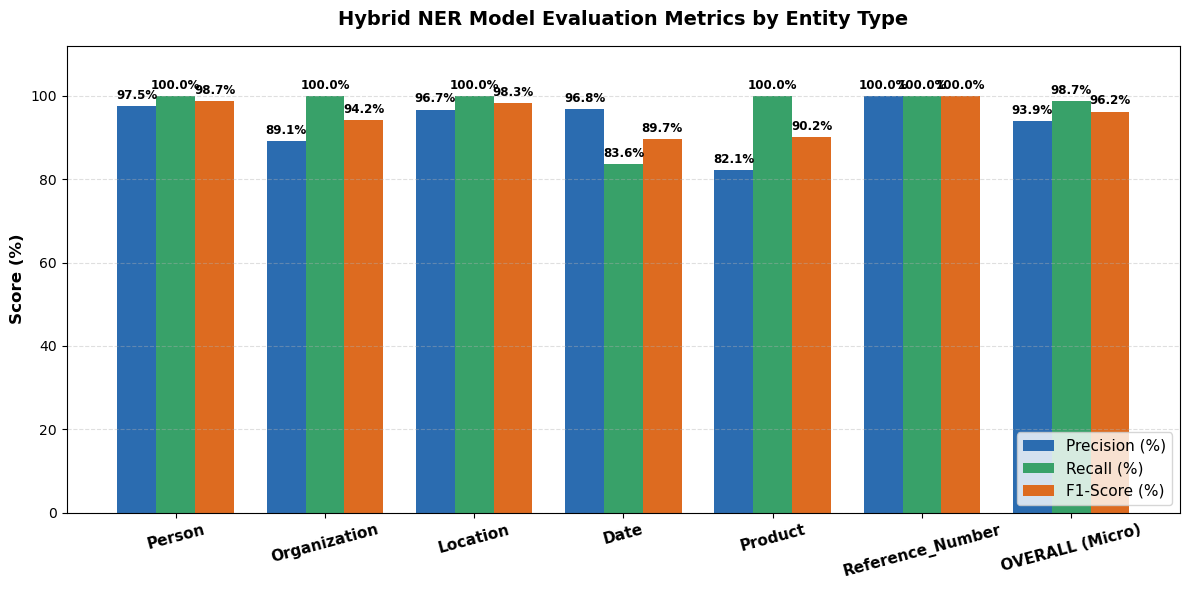

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

eval_df = pd.read_excel("ner_evaluation_results.xlsx")

entities = eval_df["Entity"]
precision = eval_df["Precision (%)"]
recall = eval_df["Recall (%)"]
f1 = eval_df["F1-Score (%)"]

x = np.arange(len(entities))
width = 0.26

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width, precision, width, label="Precision (%)", color="#2b6cb0")
rects2 = ax.bar(x, recall, width, label="Recall (%)", color="#38a169")
rects3 = ax.bar(x + width, f1, width, label="F1-Score (%)", color="#dd6b20")

ax.set_ylabel("Score (%)", fontsize=12, fontweight="bold")
ax.set_title("Hybrid NER Model Evaluation Metrics by Entity Type", fontsize=14, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(entities, rotation=15, fontsize=11, fontweight="bold")
ax.set_ylim(0, 112)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(fontsize=11, loc="lower right")

# كتابة الأرقام فوق كل عمود
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:.1f}%",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig("ner_evaluation_chart.png", dpi=300)
plt.show()

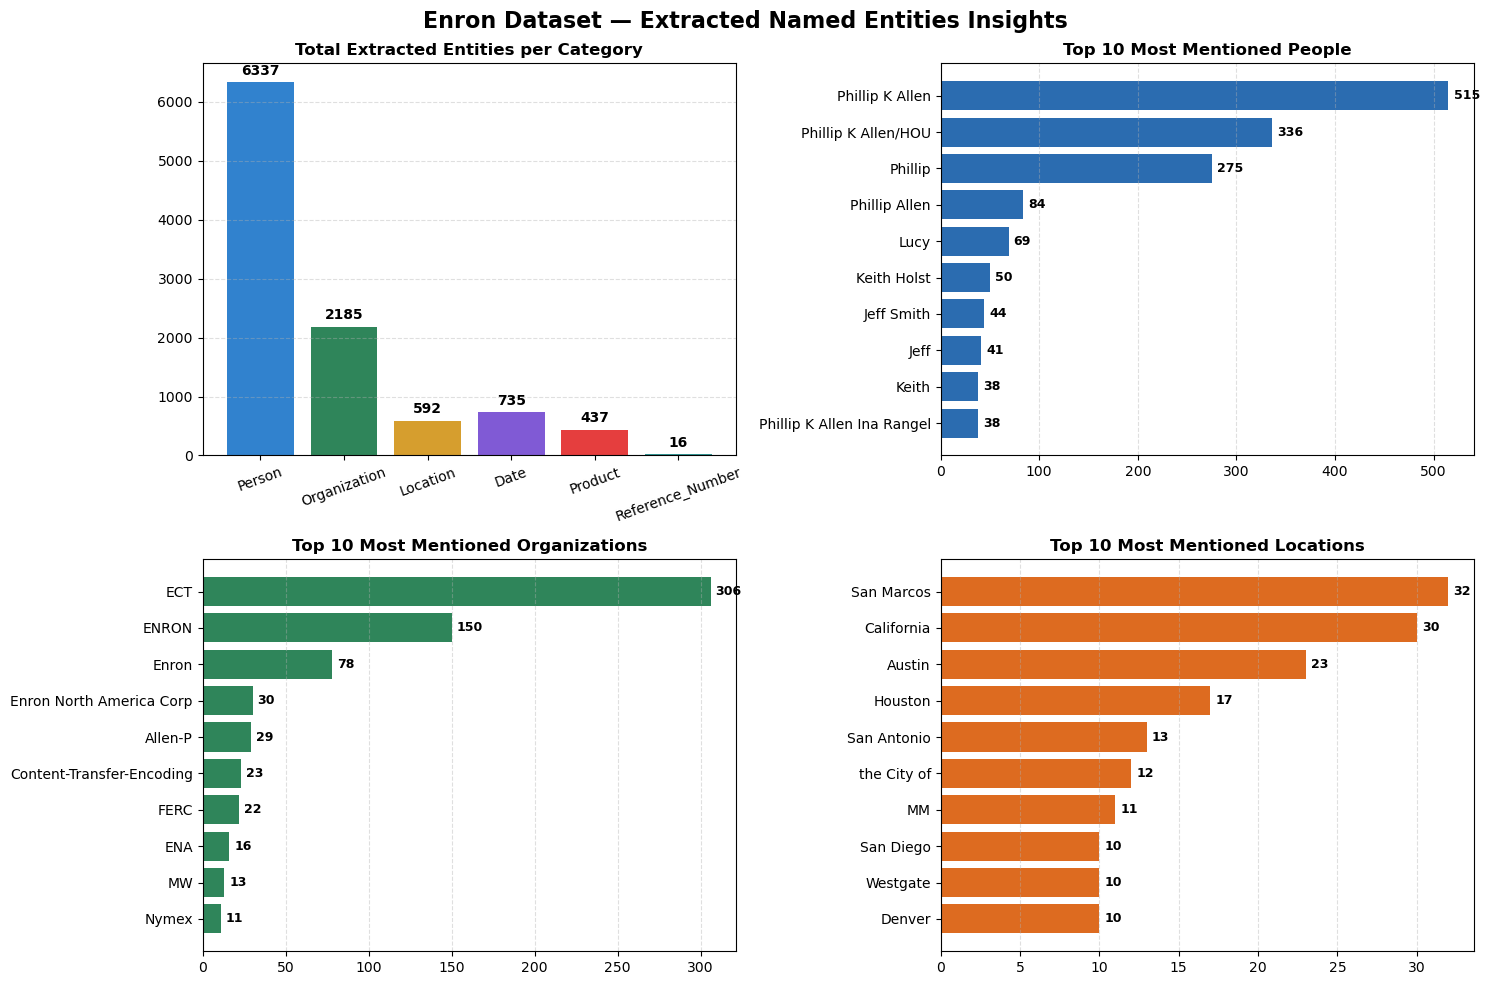

In [20]:
import ast
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd

pred_df = pd.read_csv("ner_predictions.csv")
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]

for col in ner_cols:
    pred_df[col] = pred_df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else [])

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Enron Dataset — Extracted Named Entities Insights", fontsize=16, fontweight="bold", y=0.98)

# 1. إجمالي عدد الكيانات المستخرجة لكل فئة
total_counts = {col: pred_df[col].map(len).sum() for col in ner_cols}
axes[0, 0].bar(total_counts.keys(), total_counts.values(), color=["#3182ce", "#2f855a", "#d69e2e", "#805ad5", "#e53e3e", "#319795"])
axes[0, 0].set_title("Total Extracted Entities per Category", fontsize=12, fontweight="bold")
axes[0, 0].tick_params(axis="x", rotation=20)
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.4)
for idx, v in enumerate(total_counts.values()):
    axes[0, 0].text(idx, v + (max(total_counts.values()) * 0.02), str(v), ha="center", fontweight="bold")

# دالة مساعدة لرسم Top 10
def plot_top_entities(ax, col_name, title, color):
    all_items = [item for sublist in pred_df[col_name] for item in sublist]
    top_10 = Counter(all_items).most_common(10)[::-1]
    if top_10:
        labels, counts = zip(*top_10)
        ax.barh(labels, counts, color=color)
        for i, v in enumerate(counts):
            ax.text(v + (max(counts) * 0.01), i, str(v), va="center", fontsize=9, fontweight="bold")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

# 2. أكثر 10 أشخاص ذكراً
plot_top_entities(axes[0, 1], "Person", "Top 10 Most Mentioned People", "#2b6cb0")

# 3. أكثر 10 شركات/منظمات ذكراً
plot_top_entities(axes[1, 0], "Organization", "Top 10 Most Mentioned Organizations", "#2f855a")

# 4. أكثر 10 أماكن ذكراً
plot_top_entities(axes[1, 1], "Location", "Top 10 Most Mentioned Locations", "#dd6b20")

plt.tight_layout()
plt.savefig("enron_entities_dashboard.png", dpi=300)
plt.show()

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


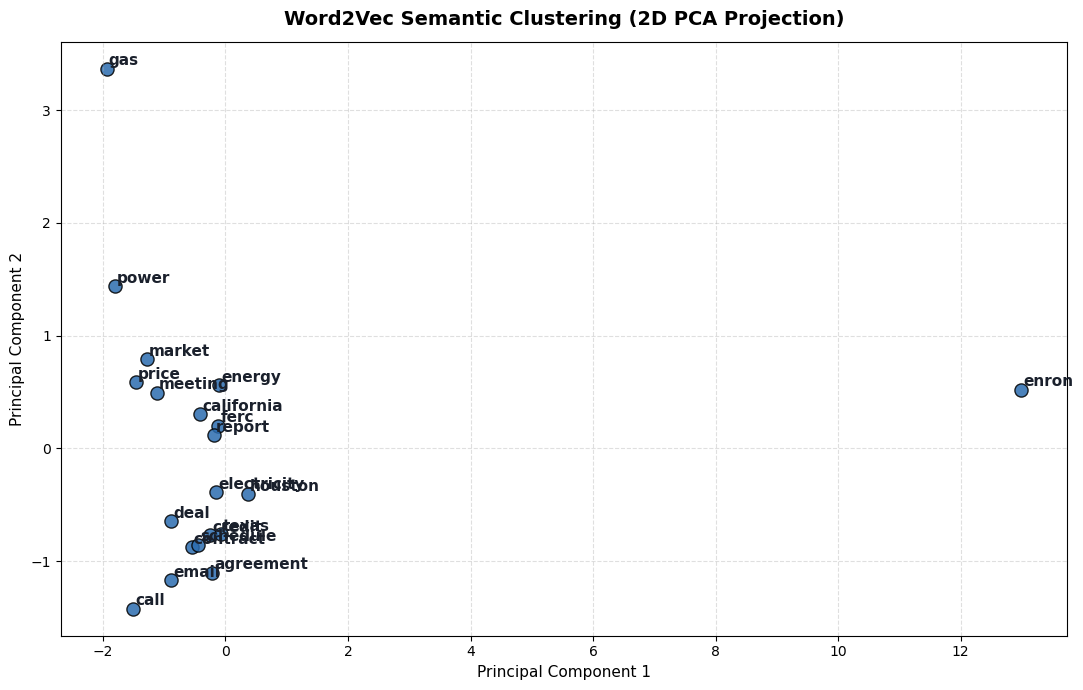

In [21]:
import ast
import matplotlib.pyplot as plt
import pandas as pd
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

df_clean = pd.read_csv("cleaned_dataset.csv")
tokens_list = df_clean["w2v_tokens"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else str(x).split()).tolist()

# تدريب أو تحميل Word2Vec على التوكنز النضيفة
w2v_model = Word2Vec(sentences=tokens_list, vector_size=100, window=5, min_count=3, workers=4, seed=42)

# اختيار كلمات مفتاحية من مجال الطاقة والإيميلات لعرض تقاربها
target_words = [
    "gas", "power", "energy", "electricity", "market",
    "contract", "deal", "price", "agreement", "credit",
    "enron", "ferc", "houston", "california", "texas",
    "meeting", "schedule", "call", "email", "report"
]
valid_words = [w for w in target_words if w in w2v_model.wv]

vectors = [w2v_model.wv[w] for w in valid_words]
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(vectors)

plt.figure(figsize=(11, 7))
plt.scatter(coords[:, 0], coords[:, 1], color="#2b6cb0", s=90, alpha=0.85, edgecolors="black")

for i, word in enumerate(valid_words):
    plt.annotate(word, (coords[i, 0] + 0.03, coords[i, 1] + 0.03), fontsize=11, fontweight="bold", color="#1a202c")

plt.title("Word2Vec Semantic Clustering (2D PCA Projection)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Principal Component 1", fontsize=11)
plt.ylabel("Principal Component 2", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("word2vec_pca_clusters.png", dpi=300)
plt.show()

In [22]:
import ast
import pandas as pd

pred_df = pd.read_csv("ner_predictions.csv")
gt_df = pd.read_excel("rich_ground_truth_25.xlsx").fillna("")
ner_cols = ["Person", "Organization", "Location", "Date", "Product", "Reference_Number"]

for col in ner_cols:
    pred_df[col] = pred_df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else [])

# 1. Example Input / Output Documents
print("=== 1. Example Input / Output Documents ===")
for i in range(3):
    print(f"\n--- Document {i+1} INPUT ---")
    print(str(pred_df.loc[i, "cleaned_text"])[:300] + "...")
    print(f"--- Document {i+1} OUTPUT ---")
    output_dict = {col: pred_df.loc[i, col] for col in ner_cols if len(pred_df.loc[i, col]) > 0}
    print(output_dict)

# 2. Error Analysis Report
merged = pd.merge(gt_df, pred_df, on="cleaned_text", suffixes=("_gt", "_pred"))
error_logs = []

for col in ner_cols:
    for _, row in merged.iterrows():
        gt_items = [x.strip().lower() for x in str(row[f"{col}_gt"]).split(",") if x.strip()]
        pred_items = [x.strip().lower() for x in row[f"{col}_pred"] if x.strip()]
        
        for p in pred_items:
            if not any(p in g or g in p for g in gt_items):
                error_logs.append({"Entity": col, "Error_Type": "False Positive (Extra)", "Value": p})
        for g in gt_items:
            if not any(p in g or g in p for p in pred_items):
                error_logs.append({"Entity": col, "Error_Type": "False Negative (Missed)", "Value": g})

error_df = pd.DataFrame(error_logs)
error_df.to_excel("error_analysis_report.xlsx", index=False)
print("\n=== 2. Common Errors Summary ===")
print(error_df.groupby(["Entity", "Error_Type"]).size())
print("\nSample Misclassified Entities:")
print(error_df.head(10))

=== 1. Example Input / Output Documents ===

--- Document 1 INPUT ---
Date: Mon, 14 May 2001 16:39:00 -0700 (PDT) From: phillip.allen@enron.com To: tim.belden@enron.com Subject: Phillip K Allen Tim Belden Here is our forecast...
--- Document 1 OUTPUT ---
{'Person': ['Phillip K Allen'], 'Date': ['14 May 2001']}

--- Document 2 INPUT ---
Date: Fri, 4 May 2001 13:51:00 -0700 (PDT) From: phillip.allen@enron.com To: john.lavorato@enron.com Subject: Re: Phillip K Allen John J Lavorato Traveling to have a business meeting takes the fun out of the trip. Especially if you have to prepare a presentation. I would suggest holding the business...
--- Document 2 OUTPUT ---
{'Person': ['Phillip K Allen', 'John J Lavorato Traveling', 'Austin'], 'Date': ['4 May 2001']}

--- Document 3 INPUT ---
Date: Wed, 18 Oct 2000 03:00:00 -0700 (PDT) From: phillip.allen@enron.com To: leah.arsdall@enron.com Subject: Re: test Phillip K Allen Leah Van Arsdall test successful. way to go!!!...
--- Document 3 OUTPUT ---


In [ ]:
!pip install -q transformers torch mlflow